# Parkinson's Disease Motion Datasets — Exploratory Data Analysis

## What is this notebook?

This is a presentation of **three original motion sources**: MMU walking poses, BMCLab optical motion capture, and a clinical pose-estimation archive. It follows the overview → duration → scores → medication → motion → animation → summary sequence in the supplied CARE-PD example. The sample's nine SMPL datasets and mesh renderer are **not** data in this project.

| Source | What is measured | Main limitation |
|---|---|---|
| MMU | 2D AlphaPose keypoints from walking videos | Source frame rate and participant IDs unavailable in inspected JSON |
| BMCLab | 3D optical markers from C3D walking trials | Marker trajectories are not a fitted body surface |
| Clinical pose | 2D CPM trajectories from clinical tasks | Original image/video is absent from the downloaded archive |

**Question for the presentation:** Which source best supports accurate 3D movement, and which best supports clinically annotated pose analysis?

**Evidence and privacy.** Figures in Sections 1–9 use a small, public aggregate snapshot in `docs/presentation_data.json`, extracted from the executed source-specific notebooks. Participant-level clinical rows and raw recordings are not included here. Section 10 displays locally generated previews and MP4s when they are available. All counts state their observation unit. No classifier or synthetic trajectory is presented.


---
## 1. Setup

Run from the repository root, or open this notebook from `notebooks/`. The aggregate sections also work in a public clone with no private source data. To show animations, first run the three source notebooks locally so `outputs/videos/` exists.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Video

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs' / 'presentation_data.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or its notebooks/ directory.')
DATA = json.loads((ROOT / 'docs' / 'presentation_data.json').read_text(encoding='utf-8'))
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'MMU': '#3268a8', 'BMCLab': '#e08035', 'Clinical pose': '#2a9d8f'}
print('Aggregate snapshot:', DATA['as_of'])
print('Presentation data: docs/presentation_data.json')


Aggregate snapshot: 2026-10-18
Presentation data: docs/presentation_data.json


---
## 2. Load all datasets — what is one observation?

The sources do **not** share a common `.pkl` or SMPL schema. The overview uses the original data inventories, while detailed motion examples come from **three selected recordings per source**. A BMCLab file can be a walking trial or a static calibration. A clinical pose entry is one task trajectory. MMU participant IDs cannot be verified from the inspected JSON files.


In [2]:
overview = pd.DataFrame(DATA['overview'])
display(overview[['dataset', 'modality', 'participants', 'participant_note', 'recordings', 'recording_unit', 'selected', 'source_fps', 'clinical_field']])
print('Total source files/trajectories across the three inventories:', int(overview.recordings.sum()))
print('The total mixes distinct recording types; it is not a pooled count of independent people or walks.')


,dataset,modality,participants,participant_note,recordings,recording_unit,selected,source_fps,clinical_field
0,MMU,2D AlphaPose,NaN,167 reported by data card; not verifiable from...,292,labeled JSON files,3,NaN,folder severity label
1,BMCLab,3D C3D markers,26.0,distinct source SUB IDs,935,"C3D files (887 walks, 48 static)",3,150.0,UPDRS-III total and walking item; ON/OFF
2,Clinical pose,2D CPM trajectories,9.0,distinct IDs in trial map,643,pose trajectories in three tasks,3,30.0,"trial-linked UPDRS, UDysRS, CAPSIT"


Total source files/trajectories across the three inventories: 1870
The total mixes distinct recording types; it is not a pooled count of independent people or walks.


---
## 3. Overview — how much material do we have?

The bars count source files or task trajectories, **not unique people**. The table above gives the participant count where verifiable. The MMU data card reports 167 people, but the inspected pose files do not independently establish that count.


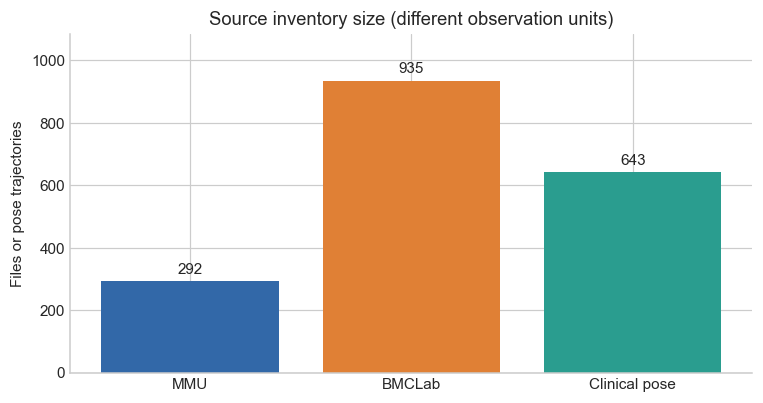

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(overview.dataset, overview.recordings, color=[COLORS[x] for x in overview.dataset])
ax.bar_label(bars, padding=3)
ax.set(ylabel='Files or pose trajectories', title='Source inventory size (different observation units)')
ax.set_ylim(0, max(overview.recordings) * 1.16)
plt.show()


---
## 4. Recording duration

The six bars below cover **selected examples only**, rather than the full source distributions. BMCLab durations use the C3D header rate of 150 Hz; clinical pose uses the reported 30 FPS capture rate. MMU is absent because its original FPS is unknown, so a real duration in seconds cannot be calculated from the inspected JSON. The table gives full-archive clinical-pose duration summaries by task.


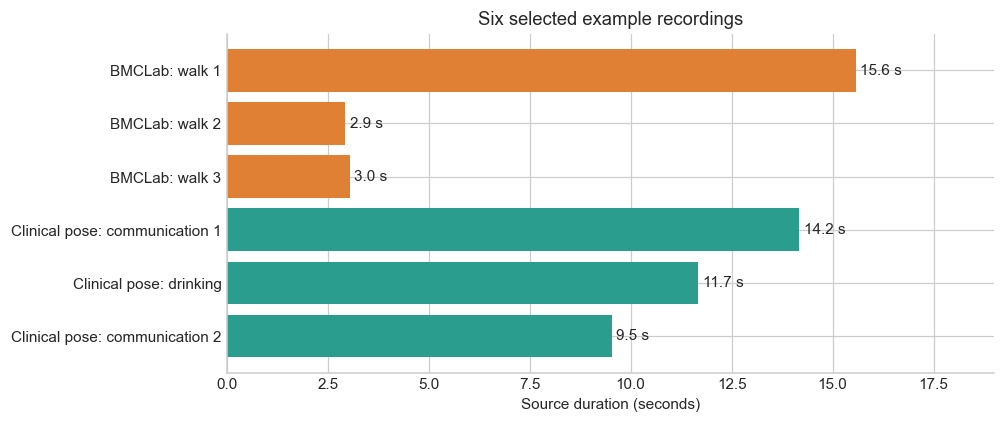

,task,trajectories,median duration (s),90th percentile (s),skewness
0,Communication,387,10.87,14.82,0.94
1,Drinking,124,6.95,11.02,1.23
2,Leg agility,132,10.55,15.07,0.41


Clinical pose pooled duration skewness: +0.58 across 643 trajectories.


In [4]:
dur = pd.DataFrame(DATA['selected_durations'])
pose_duration = pd.DataFrame(DATA['pose_duration_by_task'])
fig, ax = plt.subplots(figsize=(9, 4))
labels = dur.dataset + ': ' + dur['sample']
bars = ax.barh(labels, dur.seconds, color=[COLORS[x] for x in dur.dataset])
ax.bar_label(bars, fmt='%.1f s', padding=3)
ax.invert_yaxis()
ax.set(xlabel='Source duration (seconds)', title='Six selected example recordings')
ax.set_xlim(0, dur.seconds.max() * 1.22)
plt.show()
display(pose_duration.rename(columns={'n': 'trajectories', 'median_s': 'median duration (s)', 'p90_s': '90th percentile (s)'}).round(2))
print('Clinical pose pooled duration skewness: +0.58 across 643 trajectories.')


---
## 5. Score and label distribution

The requested **1–4 category view** is shown for every source; score **0** remains visible where the source supplies it. These four panels are intentionally separate:

- **MMU:** 1 = Normal, 2 = Mild, 3 = Moderate, 4 = Severe. These are *folder labels*, not UPDRS scores.
- **BMCLab:** source-recorded **UPDRS-III walking item** for participants rated ON or OFF medication. The total UPDRS-III score is a different measure.
- **Clinical pose:** UPDRS **gait item 3.10** is averaged across raters and can be fractional. Category 0 is exactly zero; category *k* covers `(k−1, k]`. These are display bins, not original integer ratings.

The sample notebook combines scores across studies; pooling these four panels would mix distinct clinical fields and observation units.


,category 0,category 1,category 2,category 3,category 4
source field,,,,,
MMU folder labels,NaN,150.0,29.0,61.0,52.0
BMCLab ON walking item,14.0,6.0,5.0,0.0,0.0
BMCLab OFF walking item,6.0,9.0,8.0,0.0,0.0
Clinical pose gait item bins,19.0,39.0,21.0,0.0,0.0


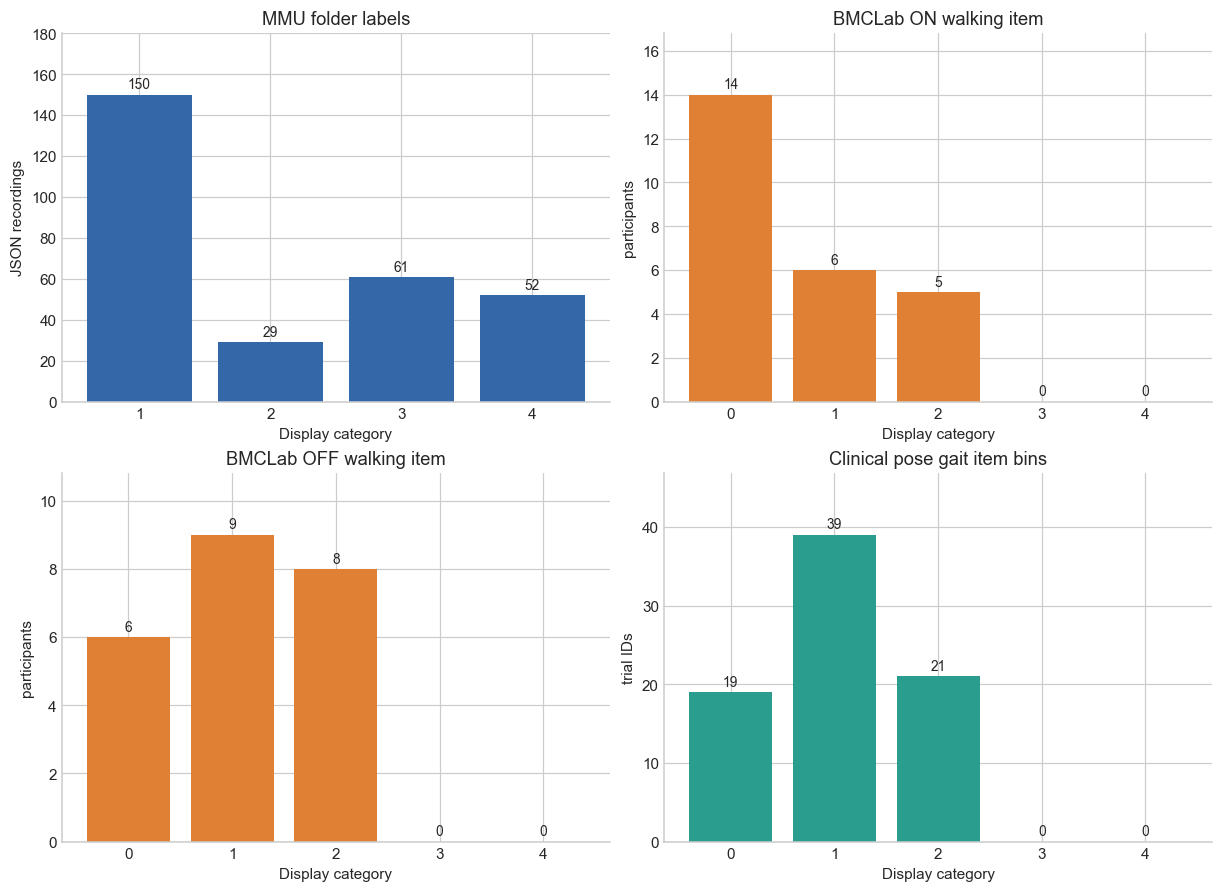

MMU class imbalance: 150/29 = 5.17:1; BMCLab scores 3 and 4 do not occur in the available metadata.


In [5]:
score = pd.DataFrame(DATA['score_categories']).T.reindex(columns=[str(i) for i in range(5)])
score.index.name = 'source field'
display(score.rename(columns=lambda x: f'category {x}'))
titles = ['MMU folder labels', 'BMCLab ON walking item', 'BMCLab OFF walking item', 'Clinical pose gait item bins']
fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for ax, title in zip(axes.flat, titles):
    counts = score.loc[title].dropna()
    color = COLORS['MMU' if title.startswith('MMU') else 'BMCLab' if title.startswith('BMCLab') else 'Clinical pose']
    bars = ax.bar(counts.index, counts.astype(int), color=color)
    ax.bar_label(bars, padding=2, fontsize=9)
    unit = 'JSON recordings' if title.startswith('MMU') else 'participants' if title.startswith('BMCLab') else 'trial IDs'
    ax.set(title=title, xlabel='Display category', ylabel=unit)
    ax.set_ylim(0, max(counts) * 1.20 if max(counts) else 1)
plt.show()
print('MMU class imbalance: 150/29 = 5.17:1; BMCLab scores 3 and 4 do not occur in the available metadata.')


### UPDRS **total** score: center and skewness

The BMCLab UPDRS-III totals are **participant-level** ON/OFF scores. Clinical pose UPDRS Total and gait item 3.10 are **trial-linked** ratings across 79 trial IDs and can repeat a person. This table reports the sample median and adjusted Fisher–Pearson skewness (`pandas.Series.skew` in the source notebooks); it does not assert that the measures are directly comparable.


,dataset,field,unit,n,median,skewness
0,BMCLab,ON UPDRS-III total,participants,25,20.00,0.43
1,BMCLab,OFF UPDRS-III total,participants,23,26.00,1.10
2,Clinical pose,UPDRS Total,trial IDs,79,21.33,1.01
3,Clinical pose,UPDRS gait item 3.10,trial IDs,79,0.67,0.59


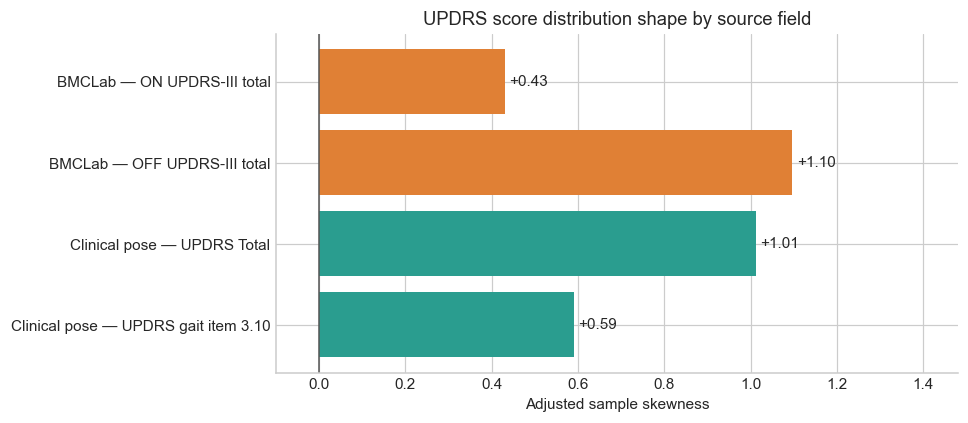

In [6]:
updrs = pd.DataFrame(DATA['updrs_summary'])
display(updrs.round({'median': 2, 'skewness': 2}))
fig, ax = plt.subplots(figsize=(8, 4))
labels = updrs.dataset + ' — ' + updrs.field
bars = ax.barh(labels, updrs.skewness, color=[COLORS[x] for x in updrs.dataset])
ax.bar_label(bars, fmt='%+.2f', padding=3)
ax.axvline(0, color='#555', linewidth=1)
ax.invert_yaxis()
ax.set(xlabel='Adjusted sample skewness', title='UPDRS score distribution shape by source field')
ax.set_xlim(-0.1, updrs.skewness.max() * 1.35)
plt.show()


---
## 6. Medication status

BMCLab source names identify ON and OFF C3D files. The inventory includes walking and static files, so these bars are **file counts**. ON and OFF total-score medians in the previous section are from participant metadata; a treatment effect cannot be inferred from either unpaired count or three selected motion examples. MMU and clinical pose do not offer the same ON/OFF file comparison here.


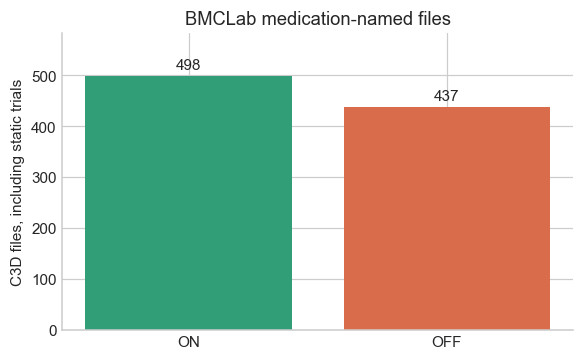

ON: 498 | OFF: 437


In [7]:
med = pd.Series(DATA['medication_file_counts'], name='C3D files')
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(med.index, med.values, color=['#329e78', '#d96c4a'])
ax.bar_label(bars, padding=3)
ax.set(ylabel='C3D files, including static trials', title='BMCLab medication-named files')
ax.set_ylim(0, med.max() * 1.17)
plt.show()
print('ON:', med['ON'], '| OFF:', med['OFF'])


---
## 7. Other clinical labels and task types

BMCLab metadata identifies 13 freezer and 13 nonfreezer participants. This is a participant grouping, not a frame-level freezing-event label in our selected C3Ds. The clinical pose archive has communication, drinking, and leg-agility trajectories. Toe tapping is represented as optical flow, so it is excluded from the full-body pose count. MMU gives the four source folder labels in Section 5.


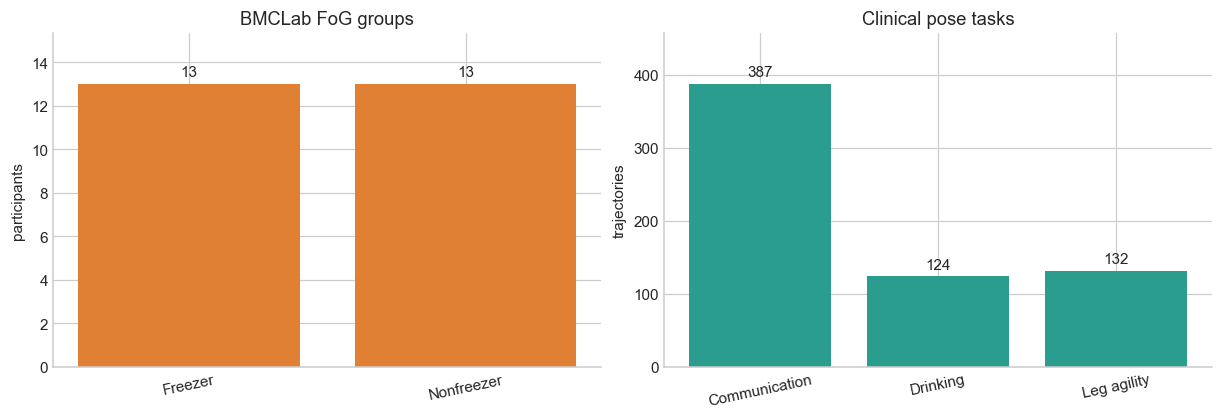

In [8]:
fog = pd.Series(DATA['fog_group_participants'])
tasks = pd.Series(DATA['clinical_pose_tasks'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for ax, counts, title, color, ylabel in [
    (axes[0], fog, 'BMCLab FoG groups', COLORS['BMCLab'], 'participants'),
    (axes[1], tasks, 'Clinical pose tasks', COLORS['Clinical pose'], 'trajectories')]:
    bars = ax.bar(counts.index, counts.values, color=color)
    ax.bar_label(bars, padding=3)
    ax.set(title=title, ylabel=ylabel)
    ax.set_ylim(0, max(counts) * 1.18)
    ax.tick_params(axis='x', rotation=12)
plt.show()


---
## 8. What does an individual recording look like?

The source-specific notebooks plot joint trajectories, displacement, elbow angles, quality, and confidence. The gallery below uses their **locally produced** plots when available; it never substitutes one source's coordinate system for another. BMCLab measures metres in 3D with source Y vertical. MMU and clinical pose have camera-pixel coordinates; MMU time in the motion plot is illustrative because its source FPS is unknown.


In [9]:
for name, title in [('mmu', 'MMU 2D pose'), ('bmclab', 'BMCLab 3D markers'), ('pose_estimation', 'Clinical 2D pose')]:
    path = ROOT / 'outputs' / 'figures' / f'{name}_movement.png'
    print(title)
    if path.exists():
        display(Image(filename=str(path), width=850))
    else:
        print('Local motion figure unavailable. Run the matching source notebook to generate it.')


MMU 2D pose


Local motion figure unavailable. Run the matching source notebook to generate it.
BMCLab 3D markers
Local motion figure unavailable. Run the matching source notebook to generate it.
Clinical 2D pose
Local motion figure unavailable. Run the matching source notebook to generate it.


---
## 9. Skewness and class imbalance

Skewness describes **numeric** distribution shape: positive means a longer right tail; negative means a longer left tail. It is not a score of disease severity. MMU folder labels are categorical, so their numeric skewness would be meaningless. The MMU frame-count skewness below uses only three deliberately selected JSONs and is not an archive-wide estimate. BMCLab trial-count skewness uses the complete inventory; clinical pose duration skewness uses all three pose tasks.


,dataset,measure,n,skewness,scope
0,MMU,selected recording frame count,3,1.19,three selected JSONs
1,BMCLab,C3D trials per participant,26,-1.37,complete archive inventory
2,BMCLab,ON UPDRS-III total,25,0.43,local metadata participants
3,BMCLab,OFF UPDRS-III total,23,1.10,local metadata participants
4,Clinical pose,trajectory duration,643,0.58,three tasks pooled
5,Clinical pose,UPDRS Total,79,1.01,trial IDs
6,Clinical pose,UPDRS gait item 3.10,79,0.59,trial IDs


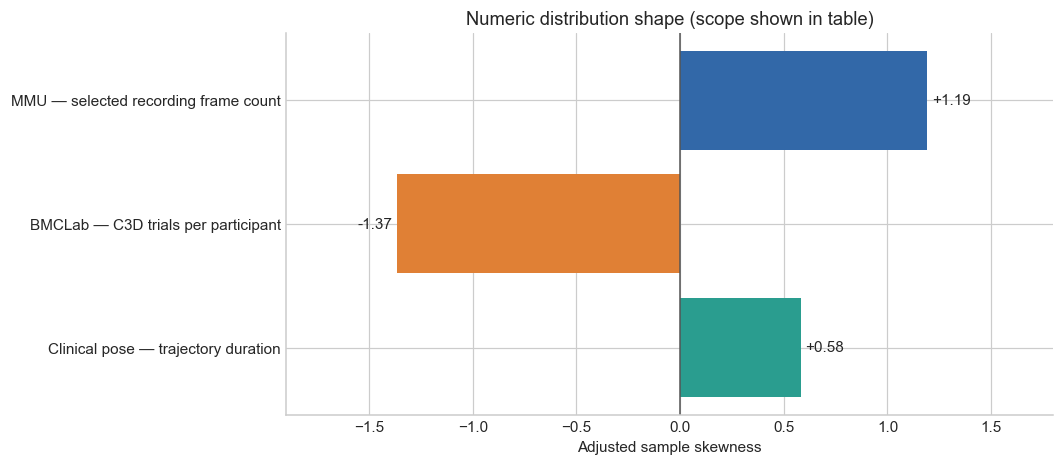

In [10]:
skew = pd.DataFrame(DATA['skewness'])
display(skew.round({'skewness': 2}))
fig, ax = plt.subplots(figsize=(9, 4.5))
base = skew[skew.measure.isin(['selected recording frame count', 'C3D trials per participant', 'trajectory duration'])].copy()
bars = ax.barh(base.dataset + ' — ' + base.measure, base.skewness,
               color=[COLORS[x] for x in base.dataset])
ax.bar_label(bars, fmt='%+.2f', padding=3)
ax.axvline(0, color='#555', linewidth=1)
ax.invert_yaxis()
ax.set(xlabel='Adjusted sample skewness', title='Numeric distribution shape (scope shown in table)')
ax.set_xlim(-1.9, 1.8)
plt.show()


---
## 10. Skeleton reconstruction and animation

Like the reference notebook, this project reconstructs visible human motion. The actual renderer is source-specific: **26 HALPE body joints** for MMU, **18 named 3D anatomical markers** for BMCLab, and **14 CPM body joints plus head and neck** for clinical pose. Each gallery image and MP4 comes from a source recording. The three videos shown below are examples; the source notebooks produced nine in total. MMU playback at 20 FPS is for viewing only. BMCLab uses measured 150 Hz timing; clinical pose uses the reported 30 FPS source timing.

Run the source notebooks first to generate local previews. This public repository intentionally does not contain individual motion frames or videos.


In [11]:
for name, title in [('mmu', 'MMU walking pose'), ('bmclab', 'BMCLab overground walking'), ('pose_estimation', 'Clinical task pose')]:
    preview = ROOT / 'outputs' / 'figures' / f'{name}_static_skeletons.png'
    video = ROOT / 'outputs' / 'videos' / name / f'{name}_01.mp4'
    print(title)
    if preview.exists():
        display(Image(filename=str(preview), width=850))
    if video.exists():
        display(Video(str(video), embed=True, width=540))
    if not preview.exists() and not video.exists():
        print('Local reconstruction unavailable; run the matching source notebook.')


MMU walking pose
Local reconstruction unavailable; run the matching source notebook.
BMCLab overground walking
Local reconstruction unavailable; run the matching source notebook.
Clinical task pose
Local reconstruction unavailable; run the matching source notebook.


---
## 11. Full 3D body mesh: feasibility

The sample notebook renders SMPL meshes because its CARE-PD data include SMPL parameters and a compatible body model. These three original sources do **not** supply a fitted SMPL mesh. BMCLab's measured 3D markers are the strongest starting point for fitting one, but fitting, registration, and separately licensed body-model assets would be required. MMU and clinical pose are 2D estimates, so a 3D surface would be inferred from images or pose, not directly measured. We therefore present faithful marker and keypoint animation, without claiming a mesh reconstruction.


---
## 12. Final summary

| Research goal | Best fit here | Evidence |
|---|---|---|
| Measured 3D walking movement | **BMCLab** | Source C3D marker coordinates, known units and 150 Hz timing |
| Accessible 2D walking pose prototype | **MMU** | 292 labeled walking-pose JSONs; true FPS and participant identity need resolution |
| Clinically annotated assessment | **Clinical pose** | Trial-linked UPDRS/UDysRS labels across several tasks |
| Future image/video VLM | **Requires original video access** | These inspected pose/C3D files do not contain the original scene imagery |

**Takeaways for the instructor.** The three datasets answer different movement questions. Score-category bars must name their source field and unit. The strongest current 3D evidence is measured BMCLab markers; the richest trial-linked clinical annotations are in the 2D clinical pose source. The nine MP4s are visualizations of authentic source coordinates, not original video or a generated SMPL body.

**Sources:** [MMU data card](https://www.kaggle.com/datasets/teeconnie/mmu-visual-based-parkinsons-disease-dataset), [BMCLab Figshare archive](https://figshare.com/articles/dataset/A_dataset_of_overground_walking_full-body_kinematics_and_kinetics_in_individuals_with_Parkinson_s_disease/14896881), [clinical pose repository](https://github.com/limi44/Parkinson-s-Pose-Estimation-Dataset). Detailed methods, quality checks, and count provenance appear in the three source notebooks and [`docs/dataset_comparison.md`](../docs/dataset_comparison.md).
